> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage4_agent_and_mcp_execution_en.ipynb`)](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/04_stage4_agent_and_mcp_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → **[▶ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb)** → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 4. [에이전트 구축 & 답변] 8종 모듈형 MCP 서버 구축 · 슬롯 검증 & 2-Pass AI FDE 에이전트 답변 생성
## Step 4.1 8종 MCP 도구 및 2-Pass 에이전트 아키텍처 구축 · Step 4.2 결정론적 산식 시뮬레이션 및 가드레일 기반 답변 생성

Stage 4는 방법론의 **Phase 6(에이전트 구축)**과 **Phase 7(답변 생성)**을 구현합니다. LLM이 위약금이나 지원금을 암산하거나 존재하지 않는 요금제를 환각하지 않도록, **(1) BigQuery 실시간 카탈로그 기반 슬롯 검증(`resolve_params`)**, **(2) 결정론적 SQL 및 바인딩 변수 기반 ISO GQL을 양대 엔진(`engine="bigquery"` 기본값 및 `engine="spanner"`)에서 실행하는 8종 모듈형 MCP 도구(`DomainMcpServer`)**, **(3) 4단계 라이프사이클로 동작하는 2-Pass Gemini(`gemini-3.8-flash`) 추론 엔진(`AiFdeAgentEngine`)**을 구축하고 정상 질의(`GROUNDED`)와 경계 질의(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)에 대한 답변을 생성합니다.

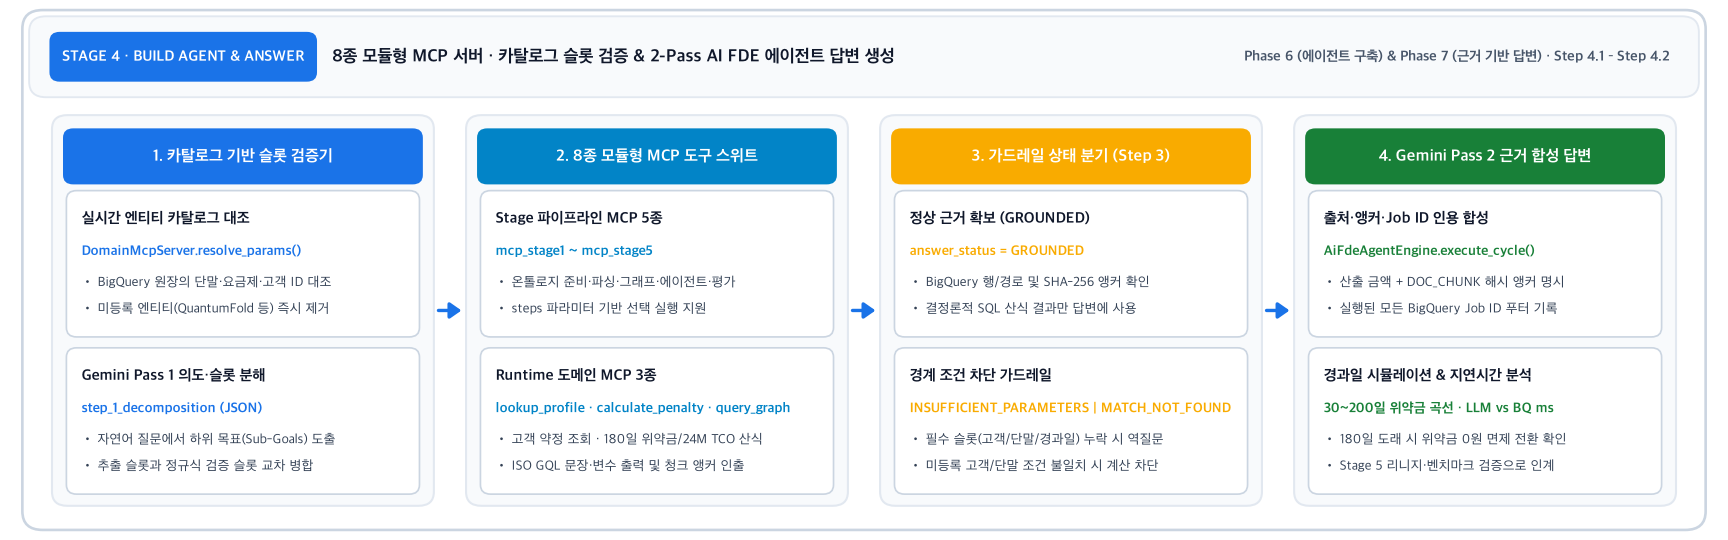


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: 에이전트 및 MCP 서버 아키텍처 구축] 2-Pass 오케스트레이션 설계도 · 8종 MCP 도구 카탈로그 · `mcp_stage4_agent_orchestration`


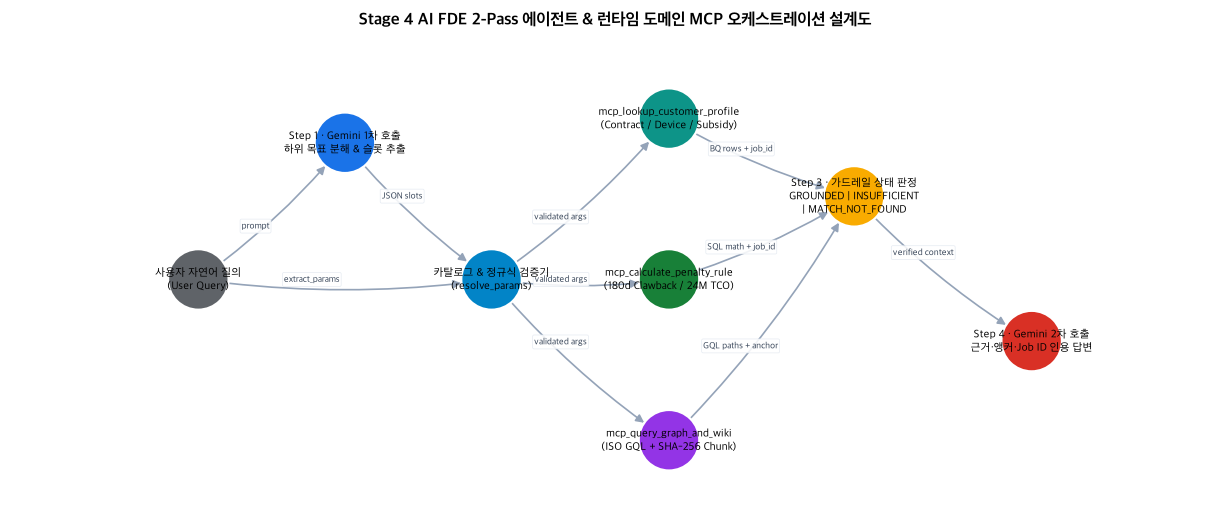

,name,stage,category,steps,spec_origin,description
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 BigQuery / Cloud Spanner 테이블 실측 프로파일링 및 고객 식별자 비식별화 규칙 검사
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS 위키 객체 목록 및 BigQuery / Spanner 문서 청크·규칙 앵커 조회
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 노드 테이블 중복 키 검사 및 Property Graph (BigQuery / Spanner) GQL 경로 수 실측
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 에이전트가 사용하는 도메인 규칙과 근거 청크를 활성 엔진(BigQuery / Spanner)에서 조회
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 고객 약정→단말·요금제·지원금→규칙→청크 리니지 조인 및 최근 검증 리포트 요약
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,고객 약정·단말 출고가·요금제별 공시지원금/추가지원금/실구매가 조회 (BigQuery / Spanner 지원)
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,180일 차액정산 위약금·특례 면제·24개월 TCO를 BigQuery 또는 Cloud Spanner SQL로 계산
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE 멀티홉 탐색(BigQuery / Spanner) 및 규칙 근거 청크 원문 조회


**`mcp_stage4_agent_orchestration`** · engine `bigquery` · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · jobs 1 (538.8 ms)

도메인 규칙 4개와 근거 청크 앵커 조회 (bigquery)

- `job_j1a4kEih0xNAuJbA57ExkCfp2UjV`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: 카탈로그 기반 슬롯 파싱 검증 (`resolve_params`)] 자연어 질문에서 안전하게 파라미터를 추출하고 미등록 엔티티를 차단하는 과정


In [3]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?,NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: 런타임 도메인 MCP 3종 직접 호출 및 GQL 문장/변수 확인] 고객 프로필 · 위약금/24개월 TCO 산식 · 그래프/위키 탐색(`executed_gql`) 및 180일 위약금 곡선


**`mcp_lookup_customer_profile`** · engine `bigquery` · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · jobs 1 (475.5 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

- `job_-RMrBzW6iSZnzQFfHNWW6KrZzZGE`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · engine `bigquery` · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · jobs 2 (997.4 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |
| `target_monthly_fee_krw` | `37000` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |
| `elapsed_days` | `120` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

- `job_mSFlPVFB5WCArd7Atair98lyLK5Y`
- `job_Oy6cuMu5g_yvAycAL7bzSEekrFM-`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · engine `bigquery` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (545.5 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

**실행된 GRAPH_TABLE / ISO GQL 문장 (Executed GQL Statement)**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `job_Sykx0GoJaQlpCErvJMRK5npxKtPY`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_ttCeM2rRmZulKZ58l7jo6ICR1J7p
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_weOVJyfQ7eUYD2VQBIWbGCirgUTJ
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_a7hdbOhv6_TnUT5BNujkxyi2HTFD
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_ISJHzlk1mQc2NpA-cfD7l9akRMz4
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_074Oj99ezfbW_EK6r-lxPIJpwX_D
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_OLG8-lviC2dpEgntIhwlb4WTOOsk
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_Vtvl4po8i9kN8D1msY6JafvmrfM3
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job__MJxU4Pp1ARMZbH8prEZCn13sRLA


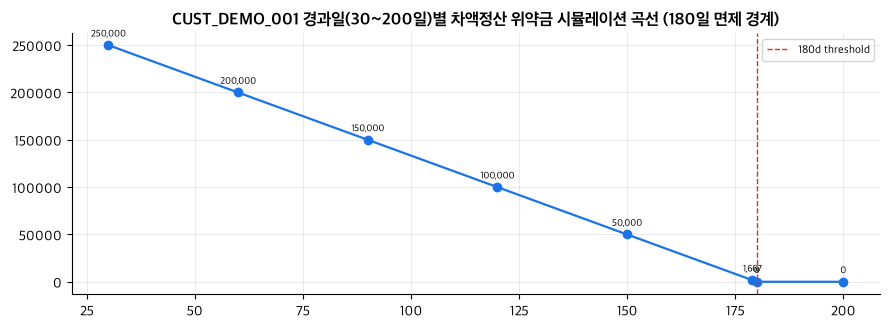

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
       vline=180, vline_label="180d threshold")


### 4. [Phase 6d: 양대 그래프 엔진 MCP 런타임 비교 (`engine="bigquery"` vs `engine="spanner"`)] Cloud Spanner Graph 직접 실행 및 결과 정합성·지연시간 대조


**`mcp_query_graph_and_wiki`** · engine `spanner` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (271.7 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

**실행된 GRAPH_TABLE / ISO GQL 문장 (Executed GQL Statement)**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `spanner:starter-spanner/starter_ontology_db@1790818724644`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,mcp_tool,bigquery_status,spanner_status,bigquery_ms,spanner_ms,bq_rows,spanner_rows,result_parity
0,mcp_lookup_customer_profile,SUCCESS,SUCCESS,495.90,1039.44,1,1,True
1,mcp_calculate_penalty_rule,SUCCESS,SUCCESS,938.29,374.92,1,1,True
2,mcp_query_graph_and_wiki,SUCCESS,SUCCESS,545.96,271.70,2,2,True


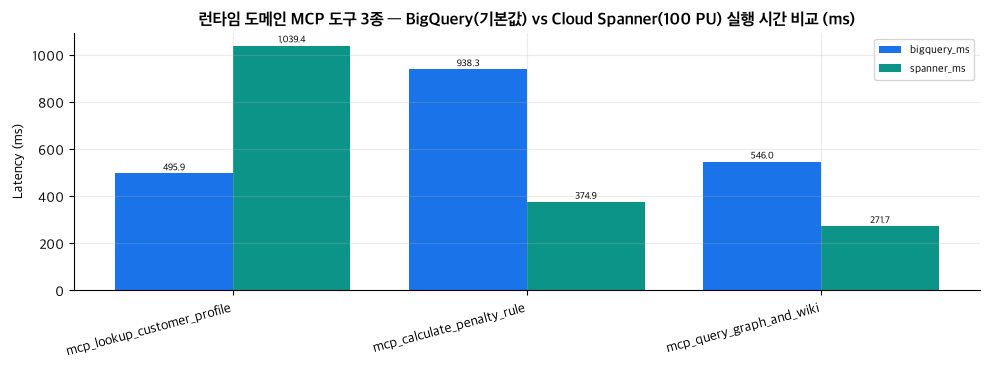

In [5]:
df_mcp_eng = H.compare_mcp_engines(server)
H.show(df_mcp_eng)
H.grouped_bar(df_mcp_eng, "mcp_tool", ["bigquery_ms", "spanner_ms"],
              "런타임 도메인 MCP 도구 3종 — BigQuery(기본값) vs Cloud Spanner(100 PU) 실행 시간 비교 (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


### 5. [Phase 7: 2-Pass 에이전트 End-to-End 답변 생성] Golden CQ(`GROUNDED`) 및 경계 조건(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`) 4단계 트레이스


#### CQ-01 (Subsidy & Net Price)
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 5 | 476 | `job_9G8ZfjeYBpiHpO2bY3LIjAUSvVTf` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 538 | `job_vAo6HxdqJapDL1_oLxJqwyw0BAJg` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 8,666 tokens, LLM 12,746 ms / total 14.22 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> 요청 조건에 명시된 **AlphaPhone 16 Pro 256GB** 및 **5G Signature 115** 요금제와 정확히 일치하는 공시지원금 정책 데이터는 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않습니다(일치 건수 0건).
>
> 대신 저장용량(256GB) 조건으로 조회된 데이터베이스 내 보유 모델 중 유사 기종인 **iPhone 16 Pro 256GB** 및 **5G Premier Essential (월 85,000원)** 정책(POL-2026-005)에 대한 지원금 및 실구매가 정보는 아래와 같습니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> **[참고: 질문과 다른 조건 (iPhone 16 Pro 256GB / 5G Premier Essential 기준)]**
> * **출고가**: 1,700,000원
> * **기본 공시지원금**: 400,000원
> * **유통망 추가지원금 상한**: 60,000원 (공시지원금의 15%)
> * **총 지원금**: 460,000원 (`400,000원 + 60,000원`)
> * **실구매가 (할부원금)**: 1,240,000원 (`1,700,000원 - 460,000원`)
> * **의무 유지 기간**: 180일
>
> *(참고: 함께 조회된 Galaxy S26 Ultra 256GB의 경우 요금제에 따라 총 지원금 172,500원 ~ 575,000원, 실구매가 1,123,400원 ~ 1,525,900원이 적용됩니다.)*
>
> ---
>
> ### **규칙·원문 근거**
> * **RULE_SUBSIDY_CAP** (`DOC_CHUNK_001`): 공시지원금 및 유통망 추가지원금 상한 정책 적용.
> * **RULE_SIX_PLAN_180D** (`DOC_CHUNK_002`): 공시지원금 수혜 시 개통일로부터 180일간 5G 기준선(45,000원/월) 이상 요금제를 유지해야 하며, 기간 내 하향 시 차액정산금이 부과됨.
> * **RULE_TCO_24M** (`DOC_CHUNK_005`): 
>   * 공시지원금 총비용 산식 = `(출고가 - 총지원금) + (월 요금 * 24)`
>   * 선택약정 총비용 산식 = `출고가 + (월 요금 * 0.75 * 24)`
>
> ---
>
> ### **관련 추가 정보**
> 1. **차액위약금 계산식 (`DOC_CHUNK_003`)**: 180일 이내에 기준선 미만 요금제로 변경할 경우 위약금은 `(초기 지원금 - 하향 요금제 지원금) * (180 - 경과일수) / 180` 공식으로 산정되며, 180일 경과 시 0원입니다.
> 2. **위약금 면제 특례 (`DOC_CHUNK_004`, RULE_WELFARE_EXEMPT)**: 만 65세 이상 시니어 또는 복지 대상자가 지정 요금제로 변경하거나 군입대 장기정지 시 위약금이 면제됩니다.
>
> ---
>
> ### **실행 정보**
> * **BigQuery Job ID**: `job_9G8ZfjeYBpiHpO2bY3LIjAUSvVTf`, `job_vAo6HxdqJapDL1_oLxJqwyw0BAJg`

#### CQ-02 (120d Prorated Penalty)
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 479 | `job_I_P5hl42YDOvoW83f8_A76LsIyZv` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 557 | `job_i0zX6qqd10HIbcAOBMkAcqJvj6fQ` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 983 | `job_ad8LCrQM8rOZy3Q8joYgg42e5qm4`, `job_RK7MWeNTA6J5oBxgg6eXnxOvAbIo` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,996 tokens, LLM 14,316 ms / total 16.34 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 **차액정산 위약금은 100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> - **고객 ID**: `CUST_DEMO_001` (계약 ID: `CONTRACT_DEMO_101`)
> - **약정 형태**: 공시지원금 (`PUBLIC_SUBSIDY`, 약정기간 24개월)
> - **개통 경과일수**: 120일 (의무유지기간: 180일)
> - **기존 요금제 및 기본 공시지원금**: 5G Premier Essential (월 85,000원 / 기본 공시지원금 450,000원)
> - **변경 대상 요금제 및 기본 공시지원금**: 5G Light (Below Baseline) (월 37,000원 / 기본 공시지원금 150,000원)
> - **기준선 요금**: 45,000원
> - **위약금 산식**:
>   $$\text{위약금} = (\text{기존 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{경과일수}}{180}$$
>   $$\text{위약금} = (450,000\text{원} - 150,000\text{원}) \times \frac{180 - 120}{180} = 300,000\text{원} \times \frac{60}{180} = 100,000\text{원}$$
>
> ---
>
> ### **규칙·원문 근거**
> - **규칙 ID**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - 조건: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - 산식: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
> - **청크 ID**: `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule)), `DOC_CHUNK_003`
>
> ---
>
> ### **관련 추가 정보**
> 1. **기준 유지 기간 경과 후 변경 시**: 180일이 경과한 후 요금제를 하향 변경하는 경우에는 차액정산 위약금이 0원입니다.
> 2. **복지 특례 적용 여부**: 고객의 복지 상태는 `NONE`이므로 시니어·복지 요금제 전환 면제 특례(`RULE_WELFARE_EXEMPT`) 대상에 해당하지 않습니다.
> 3. **24개월 총소유비용(TCO) 비교**: 기존 요금제 기준 공시지원금 선택 시 24개월 TCO는 3,220,900원이며, 선택약정 25% 할인 선택 시 TCO는 3,228,400원으로 공시지원금 이용 시 7,500원 더 저렴합니다(`RULE_TCO_24M`, `DOC_CHUNK_005`).
>
> ---
>
> ### **실행 정보**
> - **BigQuery Job ID**:
>   - 고객 프로필 조회: `job_I_P5hl42YDOvoW83f8_A76LsIyZv`
>   - 온톨로지 그래프 탐색: `job_i0zX6qqd10HIbcAOBMkAcqJvj6fQ`
>   - 위약금 및 규칙 계산: `job_ad8LCrQM8rOZy3Q8joYgg42e5qm4`, `job_RK7MWeNTA6J5oBxgg6eXnxOvAbIo`

#### CQ-03 (Welfare Exemption)
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 484 | `job_QPat-o27_0AGM1zn6fHawVjvHxCP` |
| 2 | `mcp_stage4_agent_orchestration` | `SUCCESS` | - | 465 | `job_MY39vwxibICQcRsUM9mxa-3pobUS` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 988 | `job_empMnMiw9pTFnfVPnJDgHgS57th6`, `job_wRtVpNyI_rgejg1r6ZgThnK-vgcs` |
| 4 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 543 | `job_WMoqxr_UPUII7ljn0hVnqpMsoG31` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_002'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 7,914 tokens, LLM 14,886 ms / total 17.37 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> **위약금 면제 대상이 아닙니다.** 
> 고객 `CUST_DEMO_002`의 실제 복지 상태(welfare_status)는 **`NONE`**(일반 고객)으로 등록되어 있어 복지 특례 면제 대상(`SENIOR_EXEMPT`, `MILITARY_PAUSE_ELIGIBLE`)에 해당하지 않습니다. 따라서 개통 95일 시점에 변경하려는 요금제의 월정액 조건에 따라 다음과 같이 적용됩니다:
>
> 1. **기준선(월정액 45,000원) 미만 요금제로 변경 시**: 위약금이 면제되지 않으며, 일할 차액정산 위약금이 부과됩니다.
> 2. **기준선(월정액 45,000원) 이상 요금제로 변경 시**: 180일 이내라도 기준선 이상 유지 조건을 충족하므로 차액위약금이 발생하지 않습니다(0원).
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> - **고객 ID**: `CUST_DEMO_002` (계약 ID: `CONTRACT_DEMO_102`)
> - **고객 세그먼트**: `General_Standard` / 연령대: `30s-40s`
> - **복지 등록 상태 (`welfare_status`)**: **`NONE`** (국가유공자/복지감면 대상 등록 내역 없음)
> - **약정 유형**: `PUBLIC_SUBSIDY` (공시지원금 개통)
> - **현재 이용 요금제**: `5G Premier Super` (월 130,000원)
> - **수혜 공시지원금**: 기본 500,000원 + 추가지원금 75,000원 = 총 575,000원
> - **의무유지 기준선**: 180일 / 월정액 45,000원 (`baseline_fee_krw`)
> - **요청 경과일수**: 95일 (180일 의무유지 기간 미경과)
>
> ---
>
> ### **규칙·원문 근거**
> - **`RULE_WELFARE_EXEMPT`** (청크 ID: `DOC_CHUNK_004`):
>   - **조건식**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>   - **설명**: 만 65세 이상 시니어 복지 특례 대상자 또는 군입대 장기정지 대상자만 180일 이내 위약금 100% 면제 특례를 적용받습니다. `CUST_DEMO_002`는 `welfare_status == 'NONE'`이므로 해당 규칙이 적용되지 않습니다.
> - **`RULE_SIX_PLAN_180D`** (청크 ID: `DOC_CHUNK_002`, `DOC_CHUNK_003`):
>   - **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **설명**: 공시지원금 가입자는 개통일로부터 180일 동안 기준선(5G 45,000원/월) 이상의 요금제를 유지해야 하며, 180일 이내에 기준선 미만 요금제로 하향 변경 시 일할 차액정산 위약금이 발생합니다.
>
> ---
>
> ### **관련 추가 정보 (주의사항)**
> 1. **목표 요금제 확인 필요**: 구체적인 하위 요금제가 지정되지 않아(`TARGET_PLAN_NOT_RESOLVED`), 변경하려는 요금제의 월정액이 45,000원 미만인지 여부에 따라 위약금 부과 여부 및 금액이 최종 확정됩니다.
> 2. **복지감면 자격 확인**: 시스템상 복지 상태가 `NONE`으로 등록되어 있으므로, 실제 감면 대상자라면 고객센터 또는 대리점을 통해 증빙 서류 제출 및 전산 등록이 선행되어야 합니다.
>
> ---
>
> ### **실행 정보**
> - **MCP Tool**: `mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`, `mcp_stage4_agent_orchestration`
> - **BigQuery Job IDs**: 
>   - `job_QPat-o27_0AGM1zn6fHawVjvHxCP`
>   - `job_MY39vwxibICQcRsUM9mxa-3pobUS`
>   - `job_empMnMiw9pTFnfVPnJDgHgS57th6`
>   - `job_wRtVpNyI_rgejg1r6ZgThnK-vgcs`
>   - `job_WMoqxr_UPUII7ljn0hVnqpMsoG31`

#### BC-PARAM (Missing Customer/Device)
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "target_plan_mention": "5G Lite 37"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_stage4_agent_orchestration` | `SUCCESS` | - | 465 | `job_9FXfwICExDu5Ot6-HbryyWBErPUF` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 1,002 | `job_IRVMQvs-7XRGO_utOylhNJDxgecu`, `job_wBPehEtKsslT5MQg7s06G6g8AADd` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 546 | `job_Y0OtoUFvnXOe8NGaoeEvXznE7ltX` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"target_plan_name": "5G Light (Below Baseline)", "target_plan_mention": "5G Lite 37"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 9,388 tokens, LLM 29,075 ms / total 31.09 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> **결론**  
> 개통 직후 180일 이내에 월정액 45,000원 미만 요금제인 **5G Light (37,000원)**로 하향 변경할 경우 차액정산 위약금 부과 대상입니다. 단, 현재 개통 당시의 **가입 요금제(초기 지원금)** 및 **단말기 정보**가 입력되지 않아 확정 위약금 금액 산출은 보류(DEPENDS_ON_CONTRACT)되었으며, 구체적인 위약금은 초기 지원금과 변경 요금제 지원금의 차액에 잔여일수 비율을 곱해 산정됩니다.
>
> ---
>
> ### **부족한 정보 안내 (INSUFFICIENT_PARAMETERS)**
> - 누락 항목: `customer_id 또는 단말기(+가입 요금제)`, `개통 후 경과일수`
> - 고객님의 초기 개통 요금제 및 단말기 모델에 따라 지급받은 공시지원금이 달라지므로, 해당 정보가 확인되어야 정확한 차액정산금이 계산됩니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
> - **하향 대상 요금제**: `5G Light (Below Baseline)` (월정액: 37,000원)
> - **의무유지 기준선 요금**: 45,000원
> - **의무유지 기간**: 180일
> - **예시 기준 공시지원금 (Galaxy S26 Ultra 256GB 기준 조회 데이터)**:
>   - `5G Premier Super` (월 130,000원): 총 지원금 575,000원
>   - `5G Premier Essential` (월 85,000원): 총 지원금 517,500원
>   - `5G Slim` (기준선, 월 45,000원): 총 지원금 345,000원
>   - `5G Light` (월 37,000원): 총 지원금 172,500원
>
> ---
>
> ### **규칙 및 원문 근거**
> - **적용 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   - **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **계산 산식**:  
>     $$\text{penalty} = \text{ROUND}\left((\text{initial\_base\_subsidy} - \text{lower\_tier\_base\_subsidy}) \times \frac{180 - \text{elapsed\_days}}{180}\right)$$
>   - **근거 청크**: `DOC_CHUNK_002` (anchor_3003b683cea0), `DOC_CHUNK_003` (anchor_47971ec8e4d8)
>
> ---
>
> ### **관련 추가 정보 (예외 및 주의사항)**
> 1. **180일 경과 후 변경**: 개통일로부터 180일이 경과(`elapsed_days >= 180`)한 후 요금제를 하향 변경하면 위약금은 0원입니다 (`DOC_CHUNK_003`).
> 2. **복지 특례 면제**: 만 65세 이상 시니어 또는 복지 요금제 대상자(`SENIOR_EXEMPT`)가 지정된 시니어/복지 요금제로 전환하는 경우에는 180일 이내라도 위약금이 면제(0원)됩니다 (`RULE_WELFARE_EXEMPT`, `DOC_CHUNK_004`).
> 3. **군입대 장기정지**: 현역 복무로 인한 군입대 정지 기간에는 180일 의무유지 카운트가 일시 중지되며 위약금이 발생하지 않습니다 (`DOC_CHUNK_004`).
>
> ---
>
> ### **실행 정보**
> - **BigQuery Job ID**: `job_9FXfwICExDu5Ot6-HbryyWBErPUF`, `job_wBPehEtKsslT5MQg7s06G6g8AADd`, `job_Y0OtoUFvnXOe8NGaoeEvXznE7ltX`

#### BC-NOTFOUND (Unknown Entity)
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 508 | `job_NKkLcifVCojYwDI9FBK9K2QQX6rA` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 468 | `job_lYp5ZloQqo1omUDyoAuEeT81PGcg` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 596 | `job_jIJeQqRoEdyjpDxxzVLBitPcq6DN` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"device_mention": "QuantumFold 99"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 9,982 tokens, LLM 18,990 ms / total 20.57 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 결론
> 요청하신 고객(`CUST_NOT_EXIST_999`) 및 단말기(`QuantumFold 99`)에 대한 계약 정보와 필수 파라미터가 부족하여 정확한 위약금 수치를 계산할 수 없습니다. 위약금 산정을 위해서는 아래의 부족 정보가 확인되어야 하며, 시스템에 정의된 도메인 규칙에 따른 정산 기준은 다음과 같습니다.
>
> - **개통 후 180일 이상 경과한 경우**: 위약금 0원 (전액 면제)
> - **개통 후 180일 이내에 기준선(월 45,000원) 미만 요금제로 하향 변경하는 경우**: 
>   - 산식: $\text{위약금} = (\text{초기 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{경과일수}}{180}$
>
> ---
>
> ### 근거 데이터 (BigQuery)
> 위약금 계산 모듈(`mcp_calculate_penalty_rule`) 실행 결과, 필수 입력값 부족(`INSUFFICIENT_PARAMETERS`)으로 계산이 보류되었습니다.
>
> - **부족 정보 (`missing_slots`)**:
>   - `customer_id 또는 단말기(+가입 요금제)`
>   - `개통 후 경과일수`
>   - `변경 희망 요금제`
>
> > **참고 (질문과 다른 조건)**: 현재 BigQuery 데이터베이스에 등록된 단말기 및 요금제 현황
> > - **단말기**: Galaxy S26 Ultra 256GB (1,698,400원), Galaxy S26 Ultra 512GB (1,841,400원), iPhone 16 Pro 256GB (1,700,000원), iPhone 16 Pro 512GB (2,000,000원)
> > - **요금제**: 5G Premier Super (월 130,000원), 5G Premier Essential (월 85,000원), 5G Slim (월 45,000원, 기준선), 5G Light (월 37,000원, 기준선 미만)
>
> ---
>
> ### 규칙·원문 근거
> - **`RULE_SIX_PLAN_180D` (청크 ID: `DOC_CHUNK_002`, `DOC_CHUNK_003`)**:
>   - 180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙.
>   - 공시지원금을 지급받은 가입자는 180일 동안 기준선 요금제(월 45,000원) 이상을 유지해야 하며, 180일 이내에 기준선 미만 요금제로 변경 시 잔여 일수에 비례하여 차액위약금이 부과됩니다.
> - **`RULE_SUBSIDY_CAP` (청크 ID: `DOC_CHUNK_001`)**:
>   - 공시지원금 및 유

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,lookup_customer_profile > query_graph_and_wiki,3,8666,12746,1015,14.22
1,CQ-02,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6996,14316,2019,16.34
2,CQ-03,GROUNDED,lookup_customer_profile > stage4_agent_orchestration > calculate_penalty_rule > query_...,6,7914,14886,2480,17.37
3,BC-PARAM,INSUFFICIENT_PARAMETERS,stage4_agent_orchestration > calculate_penalty_rule > query_graph_and_wiki,5,9388,29075,2013,31.09
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,9982,18990,1573,20.57


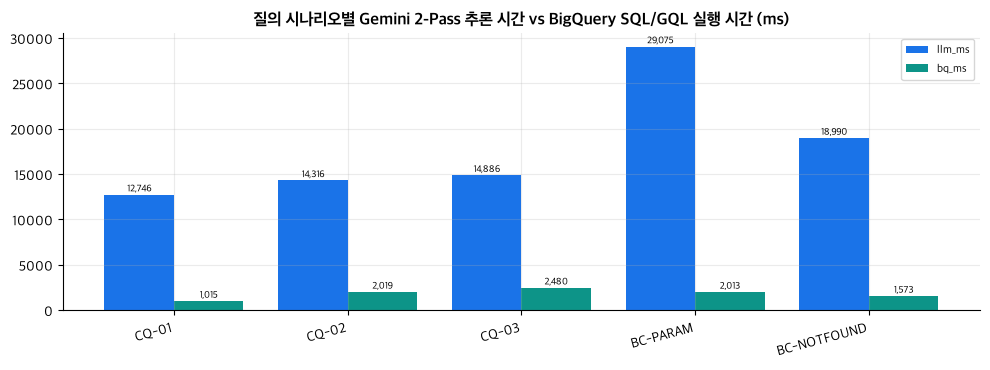

In [6]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)")


### Q&A
- **Q.** AI FDE 에이전트는 위약금 계산 오류나 미등록 단말기/고객 환각을 어떻게 방지하며, 양대 그래프 엔진(`bigquery` / `spanner`)을 어떻게 전환하나요?
  - **A.** `resolve_params()`가 실시간 카탈로그(`get_live_catalog()`)와 대조하여 미등록 단말·요금제·고객 ID를 즉시 필터링하고, 모든 금액 계산과 그래프 탐색은 8종 MCP 도구에서 `engine='bigquery'`(기본값) 또는 `engine='spanner'`를 지정해 결정론적 SQL/GQL로만 수행하며, 필수 정보 누락 시 `INSUFFICIENT_PARAMETERS`, 조건 불일치 시 `MATCH_NOT_FOUND` 상태를 반환합니다.

### Data Analysis Key Findings
- `CUST_DEMO_001` 경과일 시뮬레이션(30~200일) 결과, 위약금은 30일차 `250,000원`에서 120일차 `100,000원`, 179일차 `1,667원`으로 선형 감소하며 180일 도래 즉시 `0원`(`EXEMPT_RETENTION_COMPLETED`)으로 전환됩니다.
- 런타임 도메인 MCP 3종(`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)을 `engine='bigquery'`(기본값)와 `engine='spanner'`(`100 PU`) 양쪽에서 실행한 결과 동일한 반환 행 수(`result_parity=True`)와 SHA-256 앵커 정합성을 확인했습니다.
- Golden CQ(`CQ-01`~`CQ-03`)는 모두 `GROUNDED` 상태와 함께 정확한 금액(`575,000원`, `100,000원`, `0원`) 및 SHA-256 청크 앵커·BigQuery Job ID를 인용하여 답변했고, `BC-PARAM`과 `BC-NOTFOUND`는 수치 환각 없이 차단되었습니다.

### Insights or Next Steps
- 마지막 단계인 `Stage 5 (리니지·검증)` 노트북으로 이동하여 원천 파일부터 CQ 답변까지의 엔드투엔드 데이터 리니지 그래프와 Golden CQ 5종 / Boundary 50회 반복 벤치마크 배포 게이트를 검증하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb) ｜ [🌐 English Version](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/04_stage4_agent_and_mcp_ko.md)
